# 1st round - Step 1: reading and understanding the data

This notebook reads every file of the case study (names unchanged), checks it against the data
dictionary, profiles every column and checks the keys and links between tables. **Nothing is
changed here**: the purpose is to know the data before cleaning it. The same code runs as a script:
`python 01_data_reading.py` (reports in `reports/01_reading/`).

In [1]:
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as C
import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"{C.ROUND} - {C.MARKET} - {C.COMPETITION}")

reading = importlib.import_module("01_data_reading")

1st round - developed market - IAA AI-Assisted Hackathon 2026 - Part 1


## 1. The files
Identifiers are read as text, dates as dates, and True/False/None columns as nullable booleans.

In [2]:
data = reading.read_all()
pd.DataFrame([{"table": k, "rows": len(v), "columns": v.shape[1]} for k, v in data.items()])

  customers                 545,240 rows x 18 columns
  addresses                 575,983 rows x 16 columns


  weather                 2,879,915 rows x  9 columns
  claims                    163,150 rows x 12 columns


  policies_motor            979,968 rows x 39 columns


  policies_buildings        707,726 rows x 27 columns


  policies_contents         721,617 rows x 28 columns


  test_motor                254,986 rows x 38 columns
  test_buildings            184,155 rows x 26 columns


  test_contents             187,498 rows x 27 columns
  sample_submission         626,639 rows x  2 columns


,table,rows,columns
0,customers,545240,18
1,addresses,575983,16
2,weather,2879915,9
3,claims,163150,12
4,policies_motor,979968,39
5,policies_buildings,707726,27
6,policies_contents,721617,28
7,test_motor,254986,38
8,test_buildings,184155,26
9,test_contents,187498,27


## 2. Columns against the data dictionary
Every column should be in `config.DICTIONARY` (type and meaning), and every dictionary column in the file.

In [3]:
schema = reading.schema_check(data)
print(schema["status"].value_counts().to_string())
schema.loc[schema["status"] != "ok"]

status
ok    242


,table,column,in_dictionary,dictionary_type,dtype_read,status


## 3. Profile of every column
Missing values, distinct values, range and the most frequent values. The full table is `reports/01_reading/column_profile.csv`.

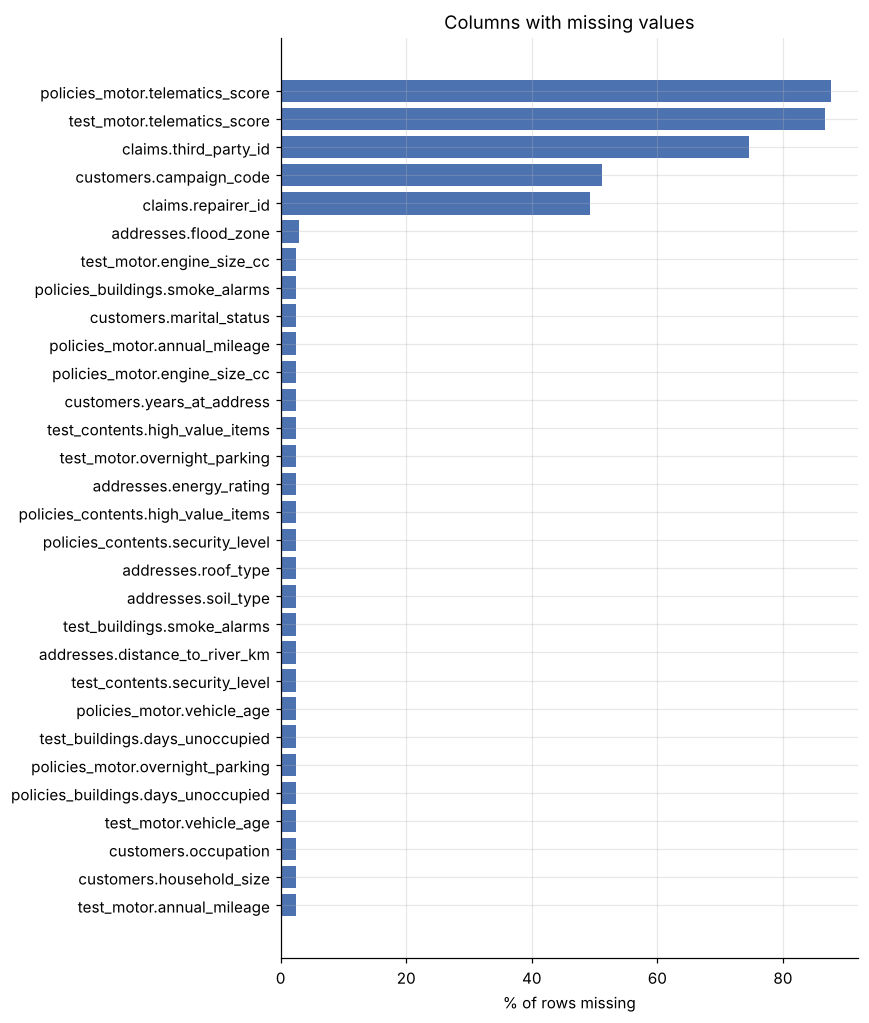

In [4]:
prof = pd.concat([H.profile(df, n) for n, df in data.items()], ignore_index=True)
miss = prof.loc[prof["missing_pct"] > 0, ["table", "column", "missing_pct", "distinct"]]
miss = miss.loc[~miss["table"].isin(["reference_policies"])].sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(8, 0.28 * len(miss) + 1))
ax.barh(miss["table"] + "." + miss["column"], miss["missing_pct"], color="#4C72B0")
ax.set_xlabel("% of rows missing"); ax.set_title("Columns with missing values")
plt.tight_layout(); plt.show()

In [5]:
prof.loc[prof["table"].isin(["policies_motor", "policies_buildings", "policies_contents"]),
         ["table", "column", "dtype", "missing_pct", "distinct", "min", "median", "max", "top_values"]]

,table,column,dtype,missing_pct,distinct,min,median,max,top_values
55,policies_motor,row_id,string,0.0,979968,NaN,NaN,NaN,M00000000 (1); M00000001 (1); M00000002 (1); M00000003 (1); M00000004 (1); M00000005 (1)
56,policies_motor,policy_id,string,0.0,308109,NaN,NaN,NaN,M23308937 (8); M21713701 (8); M20580780 (8); M78923948 (8); M98967090 (8); M45195028 (7)
57,policies_motor,customer_id,string,0.0,308109,NaN,NaN,NaN,50531880 (8); 812070 (8); 49442630 (8); 27719981 (8); 43852369 (8); 96193921 (7)
58,policies_motor,address_id,string,0.0,309499,NaN,NaN,NaN,A3513685 (24); A1373405 (23); A4266658 (23); A2901539 (22); A2831597 (21); A4954957 (21)
59,policies_motor,period_start,datetime64[s],0.0,1456,2021-01-01,NaN,2024-12-29,"2022-01-01 (199,977); 2024-01-01 (199,752); 2023-01-01 (199,609); 2021-01-01 (176,035); 2022-12-29 (208); 2023-12-30..."
...,...,...,...,...,...,...,...,...,...
144,policies_contents,days_quote_to_inception,int64,0.0,31,0.0,13.00,30.0,"0 (108,255); 1 (20,870); 26 (20,775); 23 (20,652); 20 (20,630); 9 (20,577)"
145,policies_contents,discount_applied,float64,0.0,3,0.0,0.00,0.1,"0.0 (397,407); 0.05 (287,395); 0.1 (36,815)"
146,policies_contents,written_premium,float64,0.0,31964,20.27,127.48,865.95,95.45 (82); 96.72 (81); 110.85 (81); 125.17 (80); 117.42 (80); 117.83 (79)
147,policies_contents,customer_service_contacts,int64,0.0,18,0.0,0.00,18.0,"0 (469,780); 1 (182,802); 2 (47,551); 3 (12,732); 4 (5,091); 5 (2,159)"


## 4. Keys and links between tables
Unique keys, every row's customer and address, every claim's policy, weather for every address-year on cover, the 2025 rows against the sample submission.

In [6]:
keys = reading.key_checks(data)
print(f"{int(keys['passed'].sum())} of {len(keys)} checks pass")
keys.loc[~keys["passed"]]

57 of 60 checks pass


,table,check,failures,checked,passed,detail
12,policies_motor,customer_id found in customers,98110,979968,False,"98,110 of the misses are shorter than 8 digits"
30,test_motor,customer_id found in customers,25554,254986,False,"25,554 of the misses are shorter than 8 digits"
57,claims,no claim repeated under another claim_id,604,163150,False,"claim_id lengths of the repeats: {11: 303, 10: 301}"


## 5. What will need cleaning
### 5.1 Exposure against the period dates
The 2025 files define exposure as covered days / 365. Training rows that disagree were recorded in days or on a 360-day basis.

In [7]:
recs = []
for t in [t for t in C.POLICY_TABLES if t.startswith("policies_")] + [t for t in C.POLICY_TABLES if t.startswith("test_")]:
    d = data[t]
    days = (d["period_end"] - d["period_start"]).dt.days + 1
    bad = ~np.isclose(d["exposure"], days / 365, atol=1e-3)
    recs.append({"table": t, "rows": len(d), "exposure != days/365": int(bad.sum()),
                 "of which in days": int(np.isclose(d.loc[bad, "exposure"], days[bad]).sum()),
                 "of which days/360": int(np.isclose(d.loc[bad, "exposure"], days[bad] / 360, atol=1e-3).sum())})
pd.DataFrame(recs)

,table,rows,exposure != days/365,of which in days,of which days/360
0,policies_motor,979968,5596,934,4662
1,policies_buildings,707726,4078,656,3422
2,policies_contents,721617,4206,729,3477
3,test_motor,254986,0,0,0
4,test_buildings,184155,0,0,0
5,test_contents,187498,0,0,0


### 5.2 Sums insured
On a log scale the unit errors stand apart: values hundreds to thousands of times the median (recorded in units instead of thousands), with nothing between 10x and 100x. Anything above 100x the median (dashed line) is rescaled in step 2.

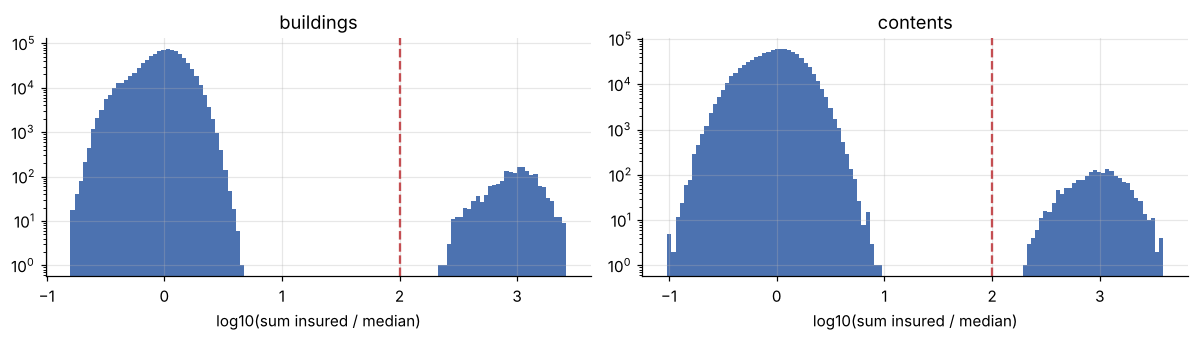

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, line in zip(axes, ["buildings", "contents"]):
    si = pd.concat([data[f"policies_{line}"]["sum_insured"], data[f"test_{line}"]["sum_insured"]])
    r = np.log10(si / si.median())
    ax.hist(r, bins=120, color="#4C72B0")
    ax.set_yscale("log"); ax.set_xlabel("log10(sum insured / median)"); ax.set_title(line)
    ax.axvline(np.log10(C.SI_UNIT_ERROR_RATIO), color="#C44E52", ls="--")
plt.tight_layout(); plt.show()

### 5.3 Identifiers
All-digit customer ids must have 8 digits. Shorter ones lost their leading zeros when stored as numbers.

In [9]:
for t in C.POLICY_TABLES:
    l = data[t]["customer_id"].str.len().value_counts().sort_index()
    print(f"{t:<20} customer_id lengths: {({int(k): int(v) for k, v in l.items()})}")

policies_motor       customer_id lengths: {2: 5, 3: 11, 4: 79, 5: 927, 6: 8958, 7: 88130, 8: 881858}
policies_buildings   customer_id lengths: {8: 707726}
policies_contents    customer_id lengths: {8: 721617}
test_motor           customer_id lengths: {2: 1, 3: 3, 4: 18, 5: 241, 6: 2316, 7: 22975, 8: 229432}
test_buildings       customer_id lengths: {8: 184155}
test_contents        customer_id lengths: {8: 187498}


### 5.4 Claims
Claims by loss year and peril; claims stored twice under a second `claim_id`; reporting delays (the slow perils are the ones still largely unreported at 31 December 2024).

In [10]:
cl = data["claims"]
display(pd.crosstab([cl["line"], cl["peril"]], cl["loss_date"].dt.year))
fields = [c for c in cl.columns if c != "claim_id"]
dup = cl.duplicated(fields, keep=False)
id_len = cl.loc[dup, "claim_id"].str.len().value_counts().sort_index()
print(f"claims identical in every field but the claim_id: {int(dup.sum())} records "
      f"(id lengths: {({int(k): int(v) for k, v in id_len.items()})})")
if dup.any():
    first = cl.loc[dup].sort_values(fields).head(4)
    display(first)
delay = (cl["report_date"] - cl["loss_date"]).dt.days
cl.assign(delay=delay).groupby(["line", "peril"])["delay"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "50%", "90%", "99%", "max"]]

loss_date                    2020   2021   2022   2023   2024
line      peril                                              
buildings accidental_damage     5    877   1010    967    989
          escape_of_water      16   2480   2569   2514   2558
          fire                  0    236    291    279    309
          flood                 4    554    593    551    530
          storm                20   1774   1996   2132   1894
          subsidence            1    283    338    381    291
contents  accidental_damage     9   2192   2291   2389   2327
          escape_of_water       8   1273   1391   1373   1362
          flood                 2    405    408    448    361
          theft                11   1780   2015   2032   2025
motor     bodily_injury        19   2146   2187   2053   1178
          glass_hail           31   3574   3990   4117   4020
          own_damage           85  12108  13170  11981  11620
          theft                12   1564   1655   1691   1579
          third_party_prop     51   8353   9100   8548   7774

claims identical in every field but the claim_id: 1208 records (id lengths: {10: 604, 11: 604})


,claim_id,policy_id,line,peril,loss_date,report_date,status,paid_to_date,incurred_to_date,recoveries,repairer_id,third_party_id
24423,CL37894154,B02582817,buildings,escape_of_water,2022-01-01,2022-01-19,closed,2667.37,2667.37,0.0,<NA>,<NA>
91020,CL136895596,B02582817,buildings,escape_of_water,2022-01-01,2022-01-19,closed,2667.37,2667.37,0.0,<NA>,<NA>
89758,CL128433556,B05076358,buildings,escape_of_water,2022-08-31,2022-09-15,closed,4291.14,4291.14,0.0,<NA>,<NA>
144666,CL00755317,B05076358,buildings,escape_of_water,2022-08-31,2022-09-15,closed,4291.14,4291.14,0.0,<NA>,<NA>


count    50%    90%     99%     max
line      peril                                                   
buildings accidental_damage   3848.0    7.0   23.0   53.53   539.0
          escape_of_water    10137.0   11.0   35.0   79.64   569.0
          fire                1115.0    4.0   12.0   26.86   515.0
          flood               2232.0    8.0   24.0   55.76   503.0
          storm               7816.0    7.0   24.0   57.00   558.0
          subsidence          1294.0   81.0  254.0  531.07   759.0
contents  accidental_damage   9208.0    7.0   24.0   56.00   557.0
          escape_of_water     5407.0   11.0   35.0   81.00   565.0
          flood               1624.0    7.0   24.0   64.08   523.0
          theft               7863.0    4.0   12.0   26.00   533.0
motor     bodily_injury       7583.0  112.0  369.0  675.26  1361.0
          glass_hail         15732.0    5.0   17.0   38.00   548.0
          own_damage         48964.0    7.0   24.0   53.00   556.0
          theft               6501.0    4.0   12.0   27.00   533.0
          third_party_prop   33826.0   14.0   47.0  104.00   649.0

Largest claim of each peril against the next one: a claim far above the rest with a small paid amount is a reserve typed with an extra digit.

In [11]:
top = (cl.sort_values("incurred_to_date", ascending=False).groupby(["line", "peril"])
       .head(2).groupby(["line", "peril"])["incurred_to_date"].apply(list))
pd.DataFrame({"largest": top.str[0], "second": top.str[1], "ratio": top.str[0] / top.str[1]}).round(1)

largest     second  ratio
line      peril                                          
buildings accidental_damage     11003.1    10294.8    1.1
          escape_of_water       66585.0    62024.9    1.1
          fire                 631246.2   466446.0    1.4
          flood                352282.0   316189.7    1.1
          storm                 41282.9    41122.4    1.0
          subsidence           207874.9   165170.5    1.3
contents  accidental_damage      9851.1     7749.7    1.3
          escape_of_water       35553.4    35145.0    1.0
          flood                111900.0    89086.4    1.3
          theft                 72189.0    50606.0    1.4
motor     bodily_injury      11894276.9  1118867.6   10.6
          glass_hail             9736.0     9590.9    1.0
          own_damage            62697.3    50643.7    1.2
          theft                 74682.0    66795.0    1.1
          third_party_prop      44546.1    42413.5    1.1

### 5.5 Driver history
The age at first licence (driver age - years licensed) cannot be below 17. In the 1st round some rows break this, and the same policy's other years show the true value. The 2nd round has age bands only.

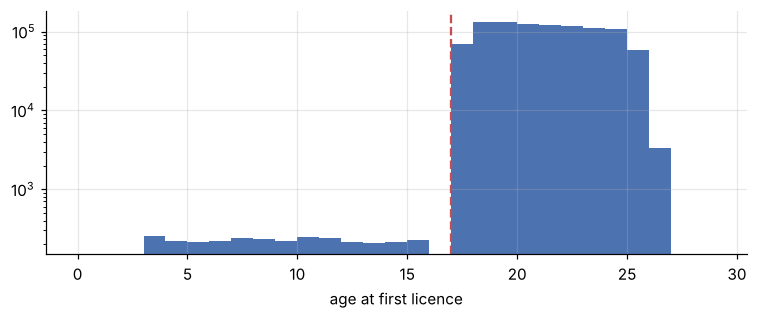

rows with a licence before 17: 2,962
no-claims bonus longer than the licence, share by driver age:
driver_age
(16, 24]     0.396
(24, 34]     0.409
(34, 49]     0.021
(49, 64]     0.000
(64, 120]    0.000


In [12]:
m = data["policies_motor"]
if "driver_age" in m:
    afl = m["driver_age"] - m["years_licensed"]
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(afl, bins=range(0, 30), color="#4C72B0"); ax.axvline(C.MIN_LICENCE_AGE, color="#C44E52", ls="--")
    ax.set_yscale("log"); ax.set_xlabel("age at first licence"); plt.tight_layout(); plt.show()
    print(f"rows with a licence before {C.MIN_LICENCE_AGE}: {int((afl < C.MIN_LICENCE_AGE).sum()):,}")
f = m["ncb_years"] > m["years_licensed"]
band = m["driver_age_band"] if "driver_age_band" in m else pd.cut(m["driver_age"], [16, 24, 34, 49, 64, 120])
print("no-claims bonus longer than the licence, share by driver age:")
print(f.groupby(band).mean().round(3).to_string())

### 5.6 Weather
One row per address and year, including 2025. The 2025 values partly lie outside the training years' range.

In [13]:
w = data["weather"]
w.groupby("year")[[c for c in C.WEATHER_VARS]].mean().round(3)

,hail_days,wind_exposure_index,freezing_days,dry_summer_index,wildfire_index,rainfall_mm,mean_temperature_c
year,,,,,,,
2021,5.638,4.599,41.274,0.493,0.178,1143.816,12.222
2022,6.725,4.507,36.978,0.470,0.145,1023.506,12.427
2023,6.256,4.390,34.705,0.549,0.132,980.688,13.085
2024,6.768,4.351,39.482,0.594,0.156,1036.392,12.972
2025,5.888,4.885,35.891,0.487,0.173,1039.975,12.618


## 6. Summary
The issues found here are fixed in step 2 (`02_data_cleaning`), each with a logged rule; the reports of this step are in `reports/01_reading/` (`schema_check.csv`, `column_profile.csv`, `key_checks.csv`, `data_dictionary.md`).